In [1]:
# Import required libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#unzip the file
import zipfile

zip_path = "/content/drive/MyDrive/CNN_Project/archive.zip"

extract_path = "/content/brain_tumor_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
import os

print(os.listdir(extract_path))

['Testing', 'Training']


In [5]:
#verify folder structure
import os

for root, dirs, files in os.walk(extract_path):
    print(root)

/content/brain_tumor_dataset
/content/brain_tumor_dataset/Testing
/content/brain_tumor_dataset/Testing/pituitary
/content/brain_tumor_dataset/Testing/notumor
/content/brain_tumor_dataset/Testing/glioma
/content/brain_tumor_dataset/Testing/meningioma
/content/brain_tumor_dataset/Training
/content/brain_tumor_dataset/Training/pituitary
/content/brain_tumor_dataset/Training/notumor
/content/brain_tumor_dataset/Training/glioma
/content/brain_tumor_dataset/Training/meningioma


In [6]:
train_path = "/content/brain_tumor_dataset/Training"
test_path = "/content/brain_tumor_dataset/Testing"

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [8]:
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

Found 4480 images belonging to 4 classes.


In [9]:
validation_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(128,128),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

Found 1120 images belonging to 4 classes.


In [10]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(128,128),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 1600 images belonging to 4 classes.


In [11]:
print(train_generator.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


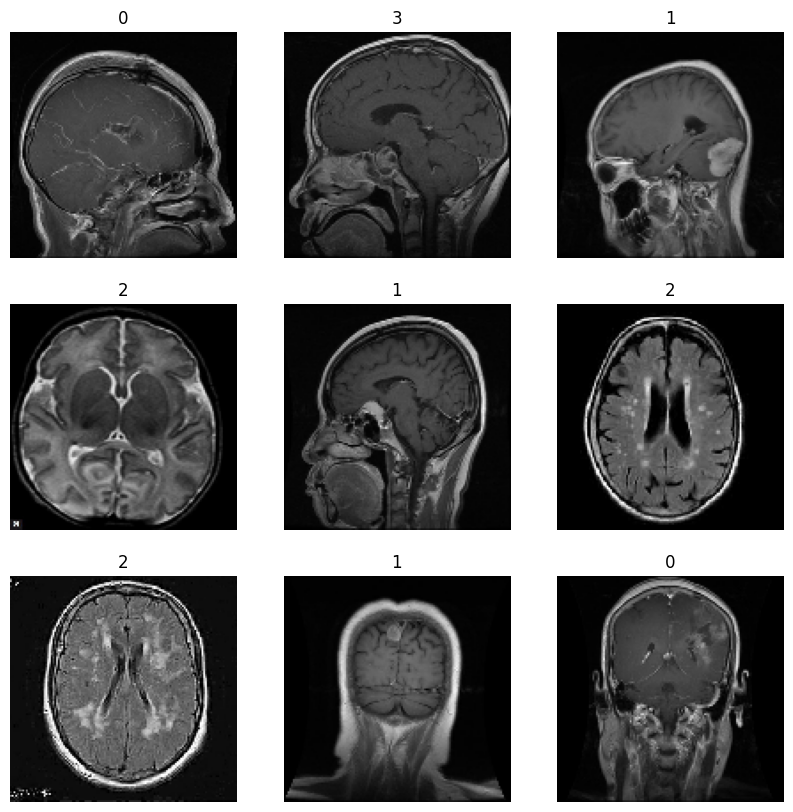

In [12]:
images, labels = next(train_generator)

plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.title(np.argmax(labels[i]))
    plt.axis("off")

plt.show()

In [13]:
#import CNN layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

In [14]:
model = Sequential([

    # First Convolution Block
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(pool_size=(2,2)),

    # Second Convolution Block
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    # Third Convolution Block
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    # Convert feature maps into a single vector
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation='relu'),

    # Reduce overfitting
    Dropout(0.5),

    # Output Layer
    Dense(4, activation='softmax')

])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.6438 - loss: 0.8329 - val_accuracy: 0.7812 - val_loss: 0.5953
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.8054 - loss: 0.5000 - val_accuracy: 0.7991 - val_loss: 0.4925
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.8460 - loss: 0.4001 - val_accuracy: 0.8580 - val_loss: 0.3633
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.8877 - loss: 0.2992 - val_accuracy: 0.8750 - val_loss: 0.3301
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.9047 - loss: 0.2479 - val_accuracy: 0.8759 - val_loss: 0.3457
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.9254 - loss: 0.2014 - val_accuracy: 0.9000 - val_loss: 0.2879
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.9422 - loss: 0.1510 - val_accuracy: 0.9125 - val_loss: 0.2731
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.9574 - loss: 0.1236 - val_accu

In [18]:
model.compile()

In [19]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 300ms/step - accuracy: 0.8819 - loss: 1.0624
Test Loss: 1.0624464750289917
Test Accuracy: 0.8818749785423279


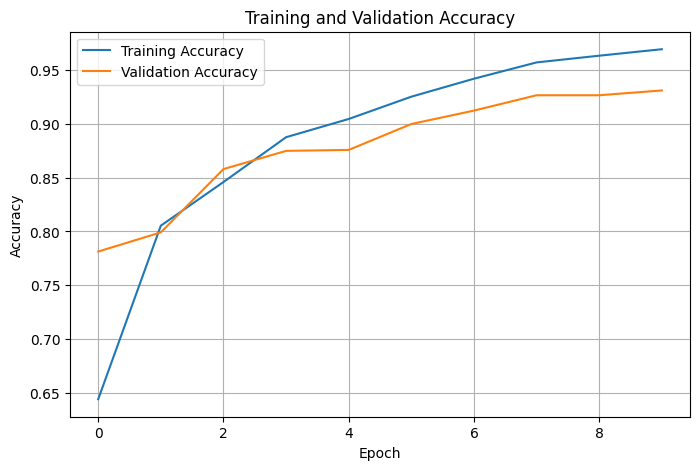

In [24]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

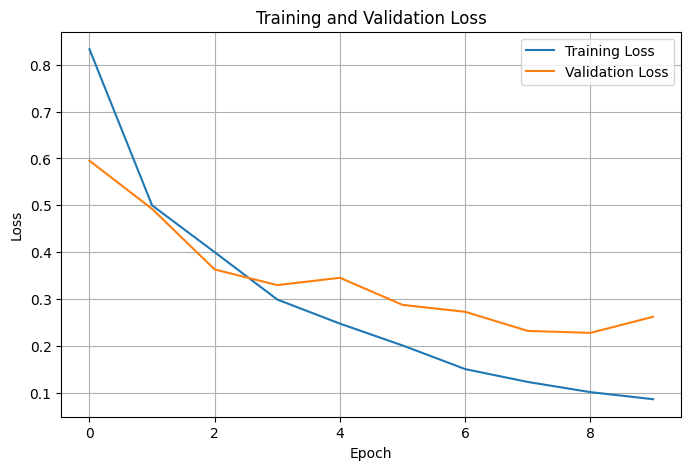

In [25]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 298ms/step


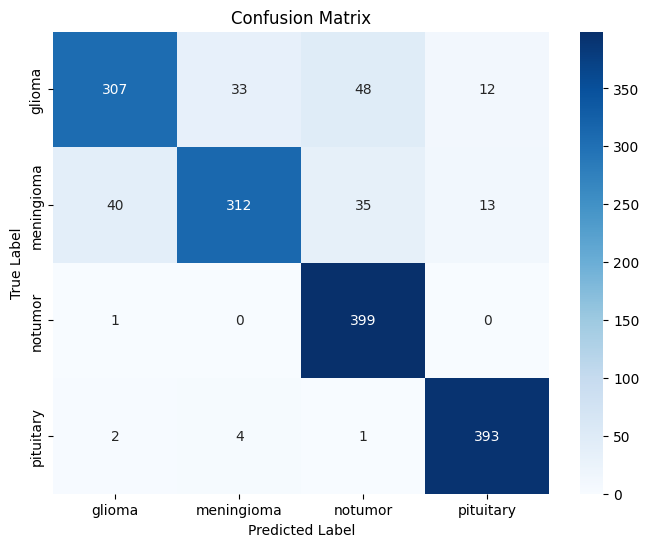

In [22]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Predict classes
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# True classes
true_classes = test_generator.classes

# Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(
    true_classes,
    predicted_classes,
    target_names=test_generator.class_indices.keys()
))

              precision    recall  f1-score   support

      glioma       0.88      0.77      0.82       400
  meningioma       0.89      0.78      0.83       400
     notumor       0.83      1.00      0.90       400
   pituitary       0.94      0.98      0.96       400

    accuracy                           0.88      1600
   macro avg       0.88      0.88      0.88      1600
weighted avg       0.88      0.88      0.88      1600



50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 362ms/step


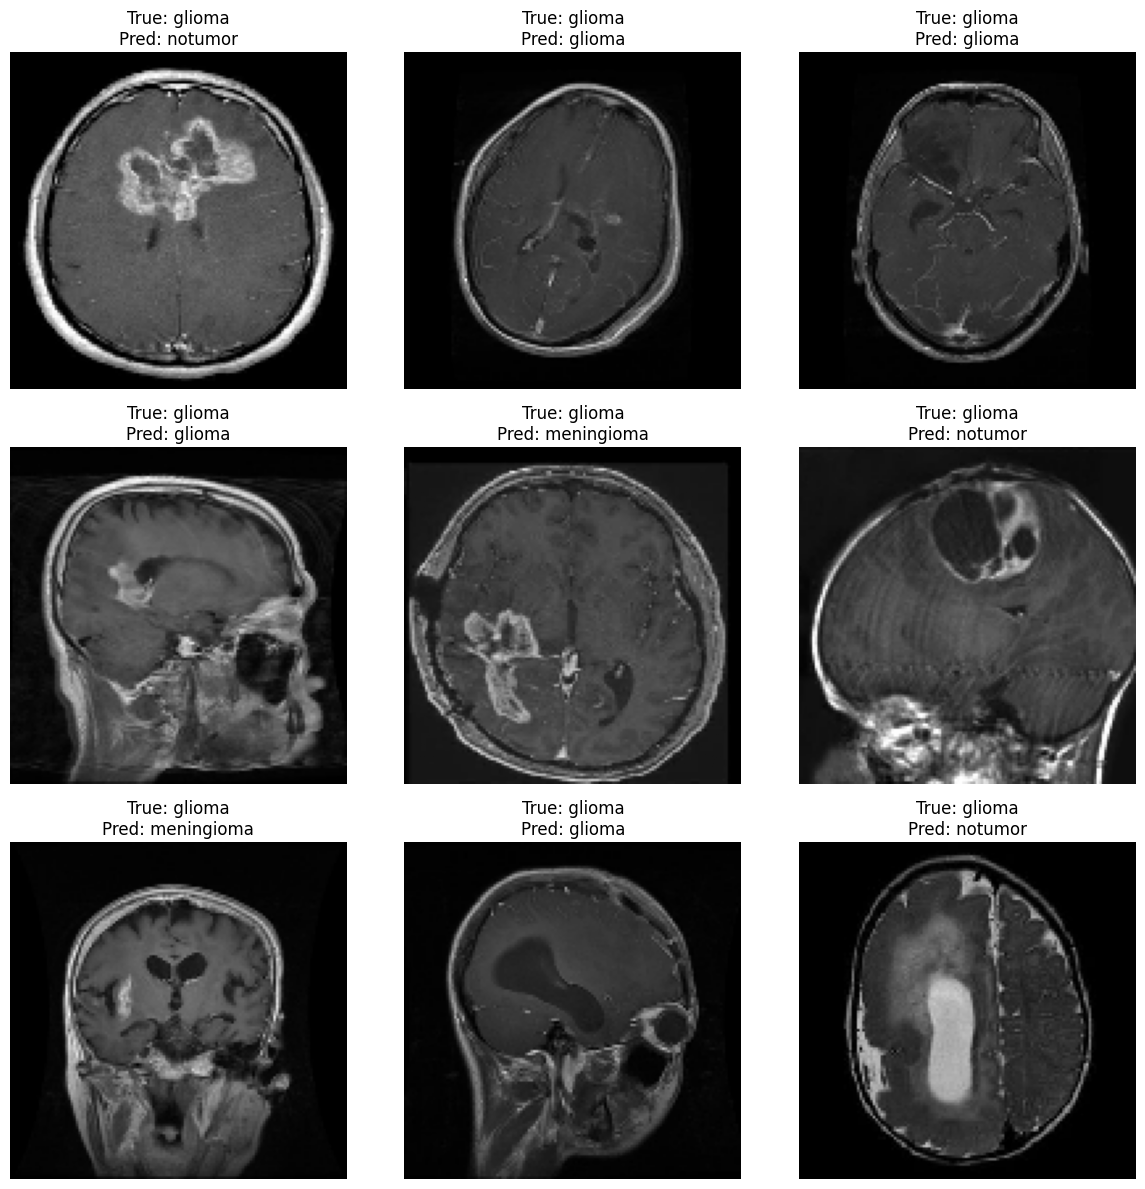

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Class labels
class_names = list(test_generator.class_indices.keys())

# Reset generator
test_generator.reset()

# Predict
predictions = model.predict(test_generator)

# Get first batch
images, labels = next(test_generator)

plt.figure(figsize=(12,12))

for i in range(9):
    plt.subplot(3,3,i+1)

    plt.imshow(images[i])

    true_label = class_names[np.argmax(labels[i])]
    predicted_label = class_names[np.argmax(predictions[i])]

    plt.title(f"True: {true_label}\nPred: {predicted_label}")

    plt.axis("off")

plt.tight_layout()
plt.show()